# Movies: what makes a film a good investment?

This notebook investigates a dataset of 3,201 films released in the US,
with box office results, production budgets, release dates, genres and
audience ratings (vega-datasets, *movies*).

**Main question:** what makes a film a good investment?
I measure this as **return on investment (ROI)**: how many dollars a film
earned for every dollar it cost to make.

**Sub-questions**
1. [Which genres give the best ROI?]
2. [Do adaptations (books, comics, remakes) pay off better than originals?]
3. [...]

**What you will find:** a first look at the data, the cleaning steps
(including impossible release dates and suspicious gross figures),
group summaries, charts, answers to the questions above, and a data note
on where the data comes from and how far it can be trusted.

**Short answer:** [write this last, 1-2 sentences]

## 0. Setup

In [63]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pandas.tseries.api import guess_datetime_format

from matplotlib.ticker import MultipleLocator

# data
movies_source = pd.read_csv("data/movies/movies.csv")
genres_source = pd.read_csv("data/movies/genre_groups.csv")
movies = movies_source.copy()
genres = genres_source.copy()

# display settings: plain numbers with thousands separators
pd.set_option("display.float_format", "{:,.1f}".format)

# seaborn settings
sns.set_theme(style="whitegrid")

## 1. Understand the data

### 1.1 What is one row?

In [64]:
display(movies.sample(5, random_state=1))
display(len(movies))

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1751,Firestorm,"8,123,860.0","8,123,860.0",NaN,"19,000,000.0",Jan 09 1998,R,NaN,20th Century Fox,Original Screenplay,Action,Contemporary Fiction,NaN,NaN,4.4,"2,118.0"
909,Star Trek: Generations,"75,671,262.0","120,000,000.0",NaN,"38,000,000.0",Nov 18 1994,PG,NaN,Paramount Pictures,Based on TV,Adventure,Science Fiction,NaN,NaN,6.5,"26,465.0"
979,Trois,"1,161,843.0","1,161,843.0",NaN,"200,000.0",Feb 11 2000,NC-17,NaN,Rainforest Productions,Original Screenplay,Thriller/Suspense,Contemporary Fiction,NaN,NaN,3.3,360.0
329,Fled,"17,192,205.0","19,892,205.0",NaN,"30,000,000.0",Jul 19 1996,R,98.0,MGM,Original Screenplay,Action,Contemporary Fiction,NaN,14.0,4.9,"4,215.0"
1885,Ghost World,"6,217,849.0","8,764,007.0",NaN,"5,500,000.0",Jul 20 2001,R,NaN,MGM,Based on Comic/Graphic Novel,Comedy,Contemporary Fiction,Terry Zwigoff,92.0,7.7,"42,973.0"


3201

Each row is one film (3,201 in total). For every film the dataset holds:
- **Money:** US and worldwide gross, US DVD sales, production budget
- **Release info:** release date, distributor, MPAA rating, running time
- **Content:** major genre, creative type, source, director
- **Reception:** Rotten Tomatoes rating (critic or audience score, to be checked), IMDB rating and votes

### 1.2 Size of the data

In [65]:
movies.shape

(3201, 16)

- The table has 3,201 rows and 16 columns.

### 1.3 Columns and data types

In [66]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   float64
 15

- `Release Date` is stored as text (`str`), but should be `datetime64` (converted in 2.1).
- `US DVD Sales` (564 of 3,201), `Running Time min` (1,209) and `Director` (1,870) are missing for many films (see section 3).
- The currency is not documented. `US Gross`, `MPAA Rating`, `US DVD Sales` and the English titles point to American data, so I assume US dollars.

### 1.4 First and last rows

In [67]:
display(movies.head())
display(movies.tail())


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,"146,083.0","146,083.0",NaN,"8,000,000.0",Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,"1,071.0"
1,"First Love, Last Rites","10,876.0","10,876.0",NaN,"300,000.0",Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,"203,134.0","203,134.0",NaN,"250,000.0",Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,"373,615.0","373,615.0",NaN,"300,000.0",Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,"1,009,819.0","1,087,521.0",NaN,"1,000,000.0",Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
3196,Zack and Miri Make a Porno,"31,452,765.0","36,851,125.0","21,240,321.0","24,000,000.0",Oct 31 2008,R,101.0,Weinstein Co.,Original Screenplay,Comedy,Contemporary Fiction,Kevin Smith,65.0,7.0,"55,687.0"
3197,Zodiac,"33,080,084.0","83,080,084.0","20,983,030.0","85,000,000.0",Mar 02 2007,R,157.0,Paramount Pictures,Based on Book/Short Story,Thriller/Suspense,Dramatization,David Fincher,89.0,NaN,NaN
3198,Zoom,"11,989,328.0","12,506,188.0","6,679,409.0","35,000,000.0",Aug 11 2006,PG,NaN,Sony Pictures,Based on Comic/Graphic Novel,Adventure,Super Hero,Peter Hewitt,3.0,3.4,"7,424.0"
3199,The Legend of Zorro,"45,575,336.0","141,475,336.0",NaN,"80,000,000.0",Oct 28 2005,PG,129.0,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,26.0,5.7,"21,161.0"
3200,The Mask of Zorro,"93,828,745.0","233,700,000.0",NaN,"65,000,000.0",Jul 17 1998,PG-13,136.0,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,82.0,6.7,"4,789.0"


- `Release Date` is written as month, day, year, e.g. "Jun 12 1998" (`%b %d %Y`).
- Why are `US Gross` and `Worldwide Gross` identical for some films? Possible reasons: either the film had no release outside the US, or the worldwide figure is missing and the US value was copied in (checked in 2.3).

### 1.5 Number summary

In [68]:
movies.describe().round(1)

,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Running Time min,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
count,"3,194.0","3,194.0",564.0,"3,200.0","1,209.0","2,321.0","2,988.0","2,988.0"
mean,"44,002,085.2","85,343,400.1","34,901,546.8","31,069,171.4",110.2,54.3,6.3,"29,908.6"
std,"62,555,311.4","149,947,342.9","45,895,121.6","35,585,913.4",20.2,28.1,1.3,"44,937.6"
min,0.0,0.0,"618,454.0",218.0,46.0,1.0,1.4,18.0
25%,"5,493,221.2","8,031,285.2","9,906,210.8","6,575,000.0",95.0,30.0,5.6,"4,828.5"
50%,"22,019,465.5","31,168,926.5","20,331,557.5","20,000,000.0",107.0,55.0,6.4,"15,106.0"
75%,"56,091,761.5","97,283,797.0","37,794,215.8","42,000,000.0",121.0,80.0,7.2,"35,810.5"
max,"760,167,650.0","2,767,891,499.0","352,582,053.0","300,000,000.0",222.0,100.0,9.2,"519,541.0"


- `US Gross` and `Worldwide Gross` have a minimum value of \$0 (checked in 2.3).
- `US Gross` has a mean of about \$44M but a median of about \$22M. The mean is about twice the median, and the max is far above the 75th percentile. This suggests a few very high-grossing films pull the mean up (examined in section 7).
- `Production Budget` has a minimum value of \$218 (checked in 2.3).

### 1.6 First look at genre_groups

In [69]:
display(genres.shape)
display(genres)
genres.info()

(12, 2)

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music
5,Action,Action & adventure
6,Adventure,Action & adventure
7,Western,Action & adventure
8,Thriller/Suspense,Thriller & horror
9,Horror,Thriller & horror


<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Major Genre  12 non-null     str  
 1   Genre group  12 non-null     str  
dtypes: str(2)
memory usage: 324.0 bytes


- The table has 12 rows and 2 columns.

## 2. Clean the data  [task 2]

### 2.1 Release Date: convert to datetime
`Release Date` is stored as text, so sorting it sorts alphabetically (Apr, Aug, Dec ...), not by date.

In [70]:
by_date = movies.sort_values("Release Date", ascending=False)[["Title", "Release Date"]]
display(by_date.head())  # newest
display(by_date.tail())  # oldest

,Title,Release Date
2585,The Queen,Sep 30 2006
2317,MirrorMask,Sep 30 2005
1412,Capote,Sep 30 2005
1783,Serenity,Sep 30 2005
2401,Into the Blue,Sep 30 2005


,Title,Release Date
117,Bang,Apr 01 1996
106,"Bright Lights, Big City",Apr 01 1988
583,My Beautiful Laundrette,Apr 01 1986
266,Death Race 2000,Apr 01 1975
876,The Sound of Music,Apr 01 1965


In [71]:
guess_datetime_format(movies["Release Date"].iloc[0])

'%b %d %Y'

- Dates are written as `%b %d %Y`, e.g. "Jun 12 1998".
- We convert to `datetime64` to be able to sort the values correctly.
- Then we sort and display again.

In [72]:
# convert to datetime
movies["Release Date"] = pd.to_datetime(
    movies["Release Date"], errors="coerce", format="%b %d %Y"
)
# Show NaT count
display(movies["Release Date"].isna().sum())
# sort by release date and display newest and oldest
by_date = movies.sort_values("Release Date", ascending=False)[["Title", "Release Date"]]
display(by_date.head())  # newest
display(by_date.tail())  # oldest

np.int64(0)

,Title,Release Date
9,Duel in the Sun,2046-12-31
90,The Best Years of Our Lives,2046-11-21
16,Wilson,2044-08-01
382,A Guy Named Joe,2043-12-24
221,Cat People,2042-11-16


,Title,Release Date
51,Alexander's Ragtime Band,1937-12-31
951,It Happened One Night,1933-12-31
572,Mata Hari,1930-12-31
404,Hell's Angels,1929-12-31
114,The Broadway Melody,1928-12-31


- We can now see release dates in the future, which is impossible.
- The dataset's last commit is 16 June 2020, so it cannot contain real release dates after that date.
- Next we count the films with impossible release dates (after 2020), and also look for strange dates before 2020.

### 2.2 Release Date: impossible years and Dec 31 placeholders

In [73]:
# films with a release date after the last commit (16 June 2020)
future_date = movies.loc[
    movies["Release Date"] > "2020-06-16", ["Title", "Release Date"]
]
display(future_date)
# count them
print(f"Count: {len(future_date)}")


,Title,Release Date
9,Duel in the Sun,2046-12-31
15,Over the Hill to the Poorhouse,2020-09-17
16,Wilson,2044-08-01
33,42nd Street,2033-03-09
85,Ben-Hur,2025-12-30
90,The Best Years of Our Lives,2046-11-21
102,The Big Parade,2025-01-01
174,"Charge of the Light Brigade, The",2036-10-20
221,Cat People,2042-11-16
337,Fantasia,2040-11-13


Count: 19


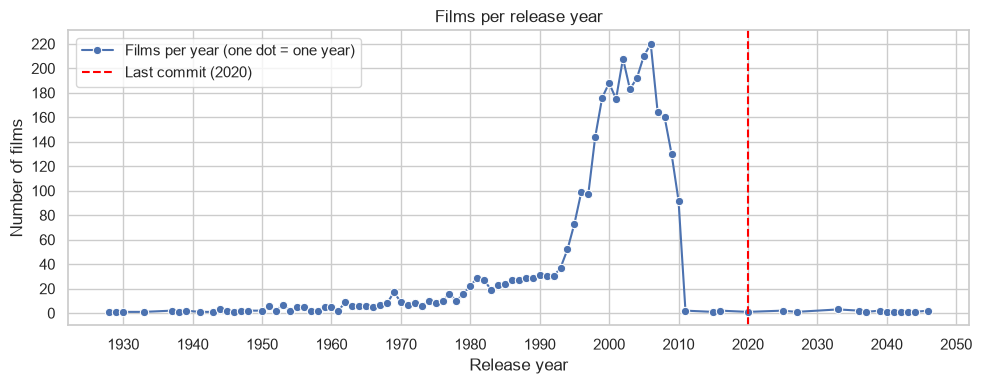

In [74]:
# films per release year (count, sorted by year)
films_per_year = movies["Release Date"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    x=films_per_year.index,
    y=films_per_year.values,
    marker="o",
    ax=ax,
    label="Films per year (one dot = one year)",
)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(20))
ax.axvline(2020, color="red", linestyle="--", label="Last commit (2020)")
ax.set_title("Films per release year")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of films")
ax.legend()
plt.tight_layout()
plt.show()

- 19 films have a release date after the last commit date of the dataset.
- Our plot shows that most of the data lies between about 1990 and 2010.
- The number of films released after 2010 is suspiciously low to be representative. This needs looking into.

In [75]:
# list films between 2011 and the last commit
suspicious = by_date.loc[by_date["Release Date"].between("2011-01-01", "2020-06-16")]
display(suspicious)

# check if those movies have values for other columns
display(movies[movies["Release Date"].between("2011-01-01", "2020-06-16")])

,Title,Release Date
26,"20,000 Leagues Under the Sea",2016-12-24
467,Intolerance,2016-09-05
120,The Birth of a Nation,2015-02-08
2967,The Adventures of Tintin: Secret of the Unicorn,2011-12-23
2658,Restless,2011-01-28


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
26,"20,000 Leagues Under the Sea","8,000,000.0","8,000,000.0",NaN,"200,000.0",2016-12-24,NaN,NaN,NaN,Based on Book/Short Story,Adventure,NaN,NaN,NaN,NaN,NaN
120,The Birth of a Nation,"10,000,000.0","11,000,000.0",NaN,"110,000.0",2015-02-08,NaN,NaN,NaN,Based on Book/Short Story,Drama,NaN,NaN,100.0,7.1,"8,901.0"
467,Intolerance,NaN,NaN,NaN,"385,907.0",2016-09-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,NaN,NaN
2658,Restless,0.0,0.0,NaN,"15,000,000.0",2011-01-28,NaN,NaN,Sony Pictures,NaN,NaN,NaN,NaN,NaN,6.7,300.0
2967,The Adventures of Tintin: Secret of the Unicorn,0.0,0.0,NaN,"130,000,000.0",2011-12-23,NaN,NaN,Paramount Pictures,Based on Comic/Graphic Novel,Adventure,Contemporary Fiction,Steven Spielberg,NaN,NaN,NaN


- All five are real films. The 1915/16 ones have plausible values, while the 2011 films lack gross and ratings (not yet released when the data was collected).
- Checked on IMDb: the three 1915/16 films are dated exactly 100 years too late, while the two 2011 films are correct.
- Since every wrong date is off by exactly 100 years, it looks like a systematic input error rather than random mistakes, so all dates after 2011 are moved back 100 years.

| Film | Dataset date | Real year (IMDb) |
|---|---|---|
| Restless | 2011 | 2011 (real) |
| The Adventures of Tintin | 2011 | 2011 (real, then upcoming) |
| The Birth of a Nation | 2015 | 1915 |
| Intolerance | 2016 | 1916 |
| 20,000 Leagues Under the Sea | 2016 | 1916 |

In [76]:
shifted = movies["Release Date"] > "2011-12-31"
print(f"Films shifted back 100 years: {shifted.sum()}")
movies.loc[shifted, "Release Date"] = movies.loc[
    shifted, "Release Date"
] - pd.DateOffset(years=100)
display(movies["Release Date"].agg(["min", "max"]))

Films shifted back 100 years: 22


min   1915-02-08
max   2011-12-23
Name: Release Date, dtype: datetime64[us]

- 22 films were corrected. The release dates now run from 1915 to 2011.

In [77]:
# how often does each calendar day occur? (all years together)
day_counts = movies["Release Date"].dt.strftime("%m-%d").value_counts()
display(day_counts.head(5))
print(f"Average films per calendar day: {len(movies) / 365:.1f}")

# flag Dec 31 dates so they can be left out of month analyses
movies["date_is_placeholder"] = movies["Release Date"].dt.strftime("%m-%d") == "12-31"

Release Date
12-31    87
12-25    50
12-17    22
11-21    20
12-15    20
Name: count, dtype: int64

Average films per calendar day: 8.8


- 87 films are dated Dec 31, about 10 times the average of about 9 films per day.
- These are probably films where only the year was known. The year is kept, but the new column `date_is_placeholder` lets us leave them out of any month analysis.

### 2.3 Money columns: zeros, identical gross and tiny budgets

In [78]:
money = ["US Gross", "Worldwide Gross", "Production Budget"]
display((movies[money] == 0).sum())  # zeros

same = movies["US Gross"] == movies["Worldwide Gross"]
print(f"US gross == worldwide gross: {same.sum()} films ({same.mean():.0%})")
display(
    movies.loc[same].nlargest(5, "US Gross")[["Title", "US Gross", "Worldwide Gross"]]
)

display(
    movies.nsmallest(5, "Production Budget")[["Title", "Production Budget", "US Gross"]]
)

US Gross             66
Worldwide Gross      47
Production Budget     0
dtype: int64

US gross == worldwide gross: 1272 films (40%)


,Title,US Gross,Worldwide Gross
924,Snow White and the Seven Dwarfs,"184,925,485.0","184,925,485.0"
984,Tootsie,"177,200,000.0","177,200,000.0"
30,3 Men and a Baby,"167,780,960.0","167,780,960.0"
905,The Sting,"159,616,327.0","159,616,327.0"
390,Gremlins,"148,168,459.0","148,168,459.0"


,Title,Production Budget,US Gross
2920,Tarnation,218.0,"592,014.0"
2387,My Date With Drew,"1,100.0","181,041.0"
802,Return to the Land of Wonders,"5,000.0","1,338.0"
6,Following,"6,000.0","44,705.0"
225,Cavite,"7,000.0","70,071.0"


- 66 films have a US Gross of 0, mostly from 2006–2009. These were probably not released or not known yet when the data was collected, so 0 means "unknown", not "earned nothing".
- 1,272 films (40%) have identical US and worldwide gross, including big hits like *Tootsie* and *Gremlins* that surely played abroad. The worldwide figure is often just a copy of the US figure.
- **Decision:** ROI is calculated on `US Gross`, which is consistent for all films.
- The smallest budget, \$218, is real: *Tarnation* (2003) is known for its tiny budget. Small budgets are kept.

In [79]:
# a gross of 0 means "unknown": turn it into a missing value
gross = ["US Gross", "Worldwide Gross"]
movies[gross] = movies[gross].mask(movies[gross] == 0)
movies[gross].isna().sum()

US Gross           73
Worldwide Gross    54
dtype: int64

- The zero values are now missing values (US Gross: 73 missing in total, Worldwide Gross: 54).

## 3. Missing values  [task 3]

### 3.1 Count missing values per column

In [80]:
missing = pd.DataFrame(
    {
        "missing": movies.isna().sum(),
        "percent": (movies.isna().mean() * 100).round(1),
    }
).sort_values("missing", ascending=False)
missing

,missing,percent
US DVD Sales,2637,82.4
Running Time min,1992,62.2
Director,1331,41.6
Rotten Tomatoes Rating,880,27.5
MPAA Rating,605,18.9
Creative Type,446,13.9
Source,365,11.4
Major Genre,275,8.6
Distributor,232,7.2
IMDB Votes,213,6.7


- Set has one movie without a Title which we can drop from the set.
- US DVD sales are missing 82.4 percent of values so it not useful - drop.

### 3.2 Decide: drop, fill or keep (and why)

In [81]:
movies = movies.dropna(subset=["Title"])  # 1 film without a title
movies = movies.drop(columns=["US DVD Sales"])  # 82% missing, not needed
print(f"Rows left: {len(movies)}")

Rows left: 3200


- Dropped the 1 film with no title, because we can't identify it.
- Dropped US DVD Sales: 82% missing, and not needed for ROI.
- Kept the gross values as missing (NaN), not filled. Filling them with a mean would invent box office numbers and skew ROI. pandas skips NaN in mean/median, so those films simply drop out of the ROI analysis.
- Kept Running Time, Director, ratings, MPAA and Creative Type as they are. They have many gaps, but filling text columns with a guess would be wrong. Groupby skips NaN groups by default.

## 4. Merge with genre groups  [task 4]

### 4.1 Merge on Major Genre and check row counts

In [82]:
rows_before = len(movies)
movies = movies.merge(genres, on="Major Genre", how="left")
print(f"Rows before: {rows_before}, after: {len(movies)}")
print(f"Films without a genre group: {movies['Genre group'].isna().sum()}")
movies["Genre group"].value_counts(dropna=False)

Rows before: 3200, after: 3200
Films without a genre group: 275


Genre group
Comedy & music        901
Drama                 789
Action & adventure    730
Thriller & horror     457
NaN                   275
Non-fiction            48
Name: count, dtype: int64

*TODO: what we see*

## 5. New columns  [task 5]

### 5.1 Release year

*TODO: what we see*

### 5.2 ROI (worldwide gross ÷ production budget)

*TODO: what we see*

## 6. Group summaries  [task 6]

### 6.1 Summary 1

*TODO: what we see*

### 6.2 Summary 2

*TODO: what we see*

### 6.3 Summary 3

*TODO: what we see*

## 7. A closer look at one column  [task 7]

### 7.1 Mean vs median

*TODO: what we see*

### 7.2 Spread and outliers

*TODO: what we see*

## 8. Charts  [task 8]

### 8.1 Chart 1

*TODO: what we see*

### 8.2 Chart 2

*TODO: what we see*

### 8.3 Chart 3

*TODO: what we see*

### 8.4 Chart 4

*TODO: what we see*

## 9. My questions  [task 9]

### Q1 ...

*TODO: what we see*

### Q2 ...

*TODO: what we see*

### Q3 ...

*TODO: what we see*

## 10. Data note  [task 10]

### 10.1 Source

*TODO: what we see*

### 10.2 Spot-checks against other sources

*TODO: what we see*

### 10.3 Limitations

*TODO: what we see*

## Conclusion
*TODO: 3-5 bullet answers to the main question*